In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

#Load data
df = pd.read_csv(r'C:\Users\ASUS\Desktop\data analysis\WA_Fn-UseC_-HR-Employee-Attrition.csv')
print(f"Shape: {df.shape}")
print(df['Attrition']. value_counts())
print(df.head())

Shape: (1470, 35)
Attrition
No     1233
Yes     237
Name: count, dtype: int64
   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7 

In [24]:
def attrition_rate (group):
    return df.groupby(group)['Attrition']. apply(lambda x: (x=='Yes').mean()*100)
print("Overall Attrition Rate: %.2f%%" % ((df['Attrition']=='Yes').mean()*100))

Overall Attrition Rate: 16.12%


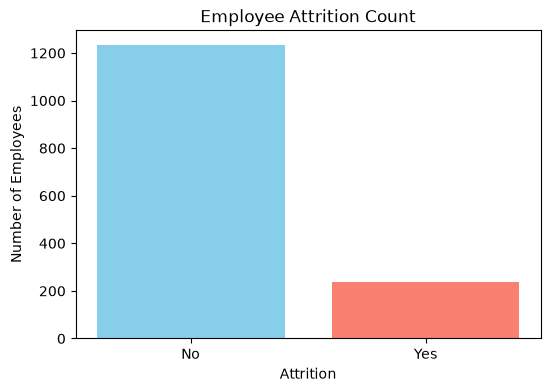

In [25]:
plt.figure(figsize=(6,4))
counts = df['Attrition']. value_counts()
plt.bar(counts.index,counts.values,color=['skyblue','salmon'])
plt.title('Employee Attrition Count')
plt.xlabel('Attrition')
plt.ylabel('Number of Employees')
plt.show()

**Insight:** 1233 employees have no attrition (stay) , only 237 have yes (leave). Most employees are retained. Attrition rate is low.

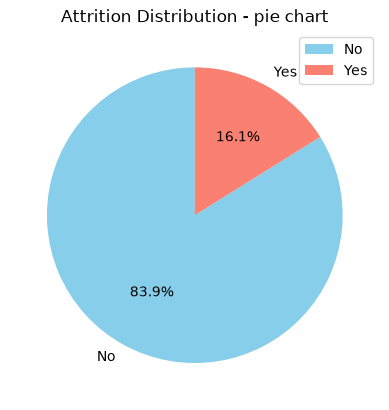

In [26]:
plt.Figure(figsize=(6,6))
plt.pie(counts.values,labels=counts.index,autopct='%1.1f%%',colors=['skyblue','salmon'], startangle=90)
plt.title('Attrition Distribution - pie chart')
plt.legend()
plt.show()

**Insight:** 84% of employees do not leave ,only 16% attrition rate.

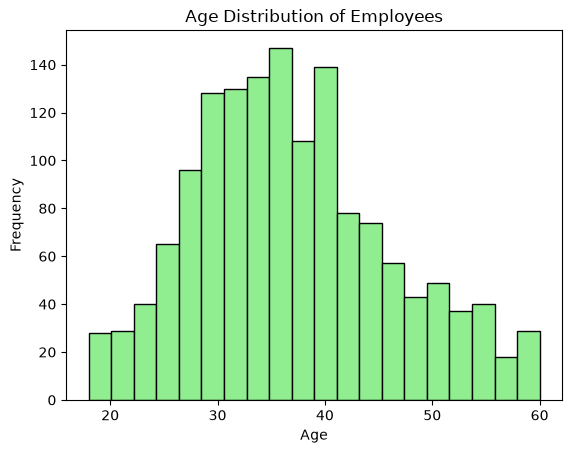

In [27]:
plt.Figure(figsize=(7,4))
plt.hist(df['Age'], bins=20, color='lightgreen', edgecolor='black')
plt.title('Age Distribution of Employees')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

**Insight:** most employees are in 30-55 age group. very few are very young (18-25) or old (55-60). Age distribution is almost normal.

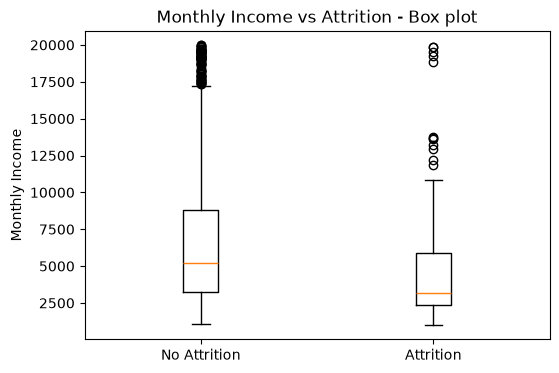

In [31]:
plt.figure(figsize=(6,4))
data_yes = df[df['Attrition']=='Yes']['MonthlyIncome']
data_no = df[df['Attrition']=='No']['MonthlyIncome']
plt.boxplot([data_no,data_yes])
plt.xticks([1,2], ['No Attrition', 'Attrition'])
plt.title('Monthly Income vs Attrition - Box plot')
plt.ylabel('Monthly Income')
plt.show()

**Insite:** Employees with No Attrition have higher monthly income (median ~4000). Employees who leave (Attrition yes) have lower income (median ~2500).many high-income outliers stayin company.

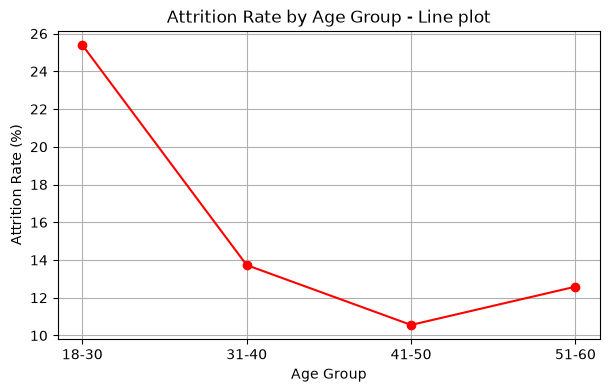

In [34]:
df['AgeGroup'] = pd.cut(df['Age'], bins=[18,30,40,50,60],labels=['18-30','31-40','41-50','51-60'])
rate_age = df.groupby('AgeGroup')['Attrition'].apply(lambda x: (x=='Yes').mean()*100)

plt.figure(figsize=(7,4))
plt.plot(rate_age.index,rate_age.values,marker='o', color='red')
plt.title('Attrition Rate by Age Group - Line plot')
plt.xlabel('Age Group')
plt.ylabel('Attrition Rate (%)')
plt.grid(True)
plt.show()

**Insight:** Attrition is highest in young employees (18-30 age group)and lowest in 41-50 age group.As age increases, attrition decreases.

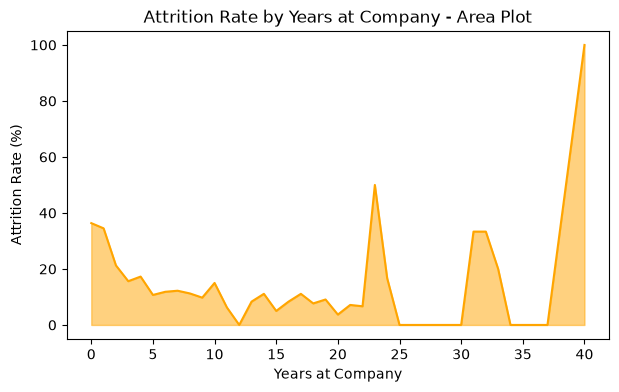

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')
rate_years = df.groupby('YearsAtCompany')['Attrition'].apply(lambda x: (x=='Yes').mean()*100)

plt.figure(figsize=(7,4))
plt.fill_between(rate_years.index,rate_years.values, color='orange',alpha=0.5)
plt.plot(rate_years.index,rate_years.values,color='orange')
plt.title('Attrition Rate by Years at Company - Area Plot')
plt.xlabel('Years at Company')
plt.ylabel('Attrition Rate (%)')
plt.show()

**Insight:** Attrition is high in first 2 years, then becomes stable.

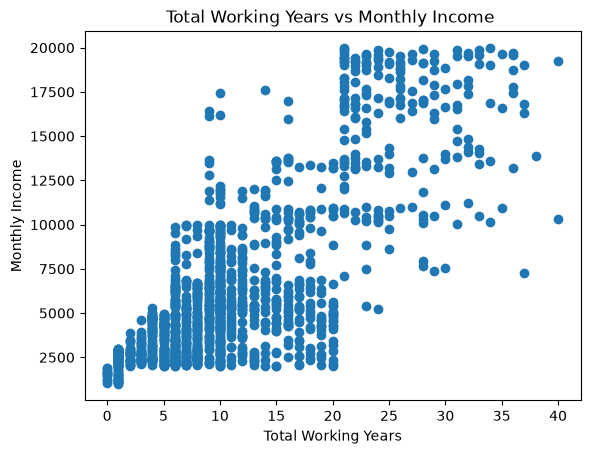

In [9]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')

plt.scatter(df['TotalWorkingYears'],df['MonthlyIncome'])
plt.title('Total Working Years vs Monthly Income ')
plt.xlabel('Total Working Years')
plt.ylabel('Monthly Income')
plt.show()

**Insight:** Higher total working years generally means higher monthly income.

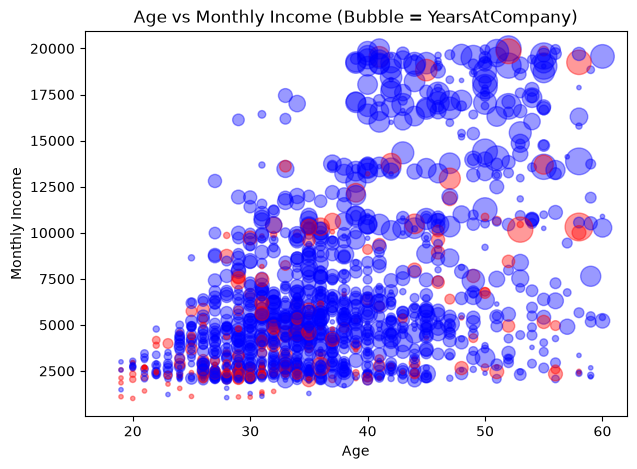

In [10]:
import numpy as np
colors = np.where(df['Attrition']=='Yes','red','blue')
plt.figure(figsize=(7,5))
plt.scatter(df['Age'], df['MonthlyIncome'], s=df['YearsAtCompany']*10, c=colors, alpha=0.4)
plt.title('Age vs Monthly Income (Bubble = YearsAtCompany)')
plt.xlabel('Age')
plt.ylabel('Monthly Income')
plt.show()

**Insight:** Bubble size shows years at company. Older employees with high income tend to stay longer.

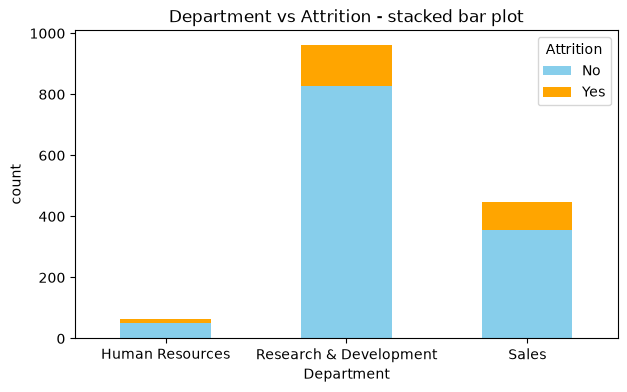

In [11]:
pd.crosstab(df['Department'], df['Attrition']).plot(kind='bar', stacked=True, color=['skyblue','orange'],figsize=(7,4))
plt.title('Department vs Attrition - stacked bar plot')
plt.xlabel('Department')
plt.ylabel('count')
plt.xticks(rotation=0)
plt.show()

**Insight:** R&D has most employees(blue = No attrition, orange = Yes attrition). Sales has relatively higher attrition.